# Data Analytics Project: [Bike Sharing Dataset]
- **Name:** Felix Baringin Jeconiah William Samosir
- **Email:** felixbaringin@student.ub.ac.id
- **ID Dicoding:** M006D4KY2445

## Menentukan Pertanyaan Bisnis

 - At what hour are bike rentals at their highest?
 - During which season does bike rental average usage increase?
 - By what percentage did total bike rentals grow in 2012 compared to 2011, and in which month was the growth highest?

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

In [2]:
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df.head(10)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
5,6,2011-01-01,1,0,1,5,0,6,0,2,0.24,0.2576,0.75,0.0896,0,1,1
6,7,2011-01-01,1,0,1,6,0,6,0,1,0.22,0.2727,0.80,0.0000,2,0,2
7,8,2011-01-01,1,0,1,7,0,6,0,1,0.20,0.2576,0.86,0.0000,1,2,3
8,9,2011-01-01,1,0,1,8,0,6,0,1,0.24,0.2879,0.75,0.0000,1,7,8
9,10,2011-01-01,1,0,1,9,0,6,0,1,0.32,0.3485,0.76,0.0000,8,6,14


### Assessing Data

In [4]:
# Day.csv data checking
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [5]:
exclude_cols = [
    "season", "yr", "hr",
    "holiday", "weekday", "workingday"
]

cols_to_check = day_df.columns.difference(exclude_cols)

summary_day = pd.DataFrame({
    "Missing (NaN)": day_df[cols_to_check].isnull().sum(),
    "Nilai 0": (day_df[cols_to_check] == 0).sum()
})

display(summary_day)

,Missing (NaN),Nilai 0
atemp,0,0
casual,0,0
cnt,0,0
dteday,0,0
hum,0,1
instant,0,0
mnth,0,0
registered,0,0
temp,0,0
weathersit,0,0


In [6]:
print("Jumlah duplikasi: ",day_df.duplicated().sum())

Jumlah duplikasi:  0


In [7]:
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [8]:
cols_to_check = hour_df.columns.difference(exclude_cols)

summary_hour = pd.DataFrame({
    "Missing (NaN)": hour_df[cols_to_check].isnull().sum(),
    "Nilai 0": (hour_df[cols_to_check] == 0).sum()
})

display(summary_hour)

,Missing (NaN),Nilai 0
atemp,0,2
casual,0,1581
cnt,0,0
dteday,0,0
hum,0,22
instant,0,0
mnth,0,0
registered,0,24
temp,0,0
weathersit,0,0


In [9]:
print("Duplicated Records: ",day_df.duplicated().sum())

Duplicated Records:  0


In [10]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [11]:
print("Jumlah duplikasi: ",hour_df.duplicated().sum())

Jumlah duplikasi:  0


In [12]:
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


### Data Assessing Results

- There is a data type error in the dteday column. Its data type should be datetime, not object.
- There are no missing values in either dataset.
- Several columns contain values of 0. This needs attention if a deeper analysis is to be performed on all parameters, such as temperature, humidity, and windspeed.
- The hour.csv dataset has a total of 17,379 records, whereas there should be 17,544 records covering every hour over 2 years. 165 records were not recorded. However, a comparison with day.csv shows no difference in user data. This can be seen in the casual, registered, and cnt columns, which have the same totals in both datasets.

### Cleaning Data

In [13]:
datetime_columns = ["dteday"]

for column in datetime_columns:
  day_df[column] = pd.to_datetime(day_df[column])

In [14]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[ns]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[ns](1), floa

In [15]:
datetime_columns = ["dteday"]

for column in datetime_columns:
  hour_df[column] = pd.to_datetime(hour_df[column])

In [16]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[ns]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-

## Exploratory Data Analysis (EDA)

### Peak Hours


In [17]:
non_working_days = (
    hour_df[hour_df['workingday'] == 0].groupby('hr')[['cnt']].sum().reset_index()
)

display(non_working_days)

,hr,cnt
0,0,20884
1,1,15987
2,2,12123
3,3,5851
4,4,1876
5,5,1929
6,6,4292
7,7,10027
8,8,24406
9,9,39645


In [18]:
working_days = (
    hour_df[hour_df['workingday'] == 1].groupby('hr')[['cnt']].sum().reset_index()
)

display(working_days)

,hr,cnt
0,0,18246
1,1,8177
2,2,4229
3,3,2323
4,4,2552
5,5,12332
6,6,50840
7,7,144144
8,8,236595
9,9,119793


### Rentals by Season

In [19]:
rental_by_season = (
    day_df.groupby('season')['cnt'].mean().round(2).reset_index()
)

display(rental_by_season)

,season,cnt
0,1,2604.13
1,2,4992.33
2,3,5644.30
3,4,4728.16


### Annual Total Bike Rentals

In [20]:
total = (day_df.groupby('yr')['cnt'].sum().reset_index())
display(total)

,yr,cnt
0,0,1243103
1,1,2049576


### Annual Bike Rentals Comparison

In [21]:
rented_comp = (
    day_df.groupby(['yr', 'mnth'])[['cnt']].sum().reset_index()
)
display(rented_comp)

,yr,mnth,cnt
0,0,1,38189
1,0,2,48215
2,0,3,64045
3,0,4,94870
4,0,5,135821
5,0,6,143512
6,0,7,141341
7,0,8,136691
8,0,9,127418
9,0,10,123511


### 2011-2012 Bike Rentals

In [22]:
total_rent = (
    day_df.groupby(['yr', 'mnth'])[['casual', 'registered']].sum().reset_index()
)

display(total_rent)

,yr,mnth,casual,registered
0,0,1,3073,35116
1,0,2,6242,41973
2,0,3,12826,51219
3,0,4,22346,72524
4,0,5,31050,104771
5,0,6,30612,112900
6,0,7,36452,104889
7,0,8,28842,107849
8,0,9,26545,100873
9,0,10,25222,98289


## Visualization & Explanatory Analysis

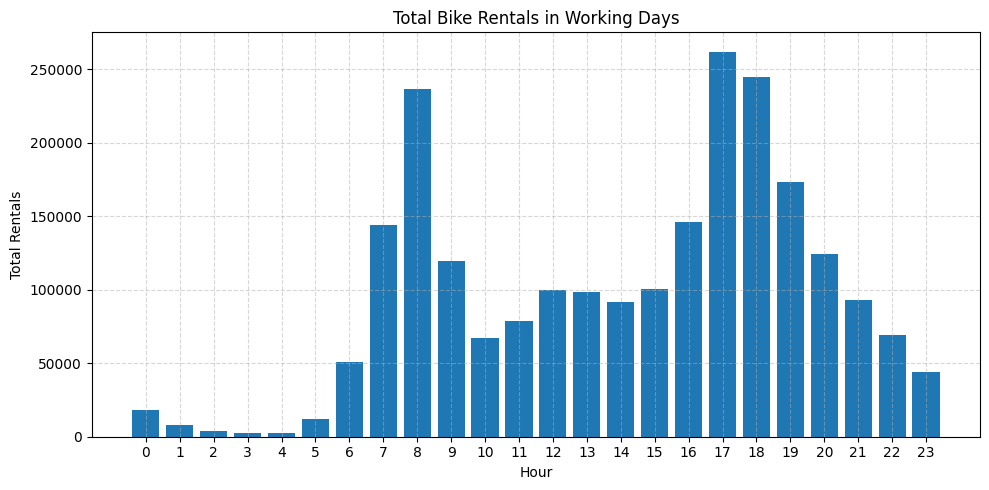

In [23]:
plt.figure(figsize=(10, 5))

plt.bar(
    working_days['hr'],
    working_days['cnt'],
)

plt.title('Total Bike Rentals in Working Days')
plt.xlabel('Hour')
plt.ylabel('Total Rentals')
plt.xticks(range(24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('peak_hours.png', dpi=300)
plt.show()

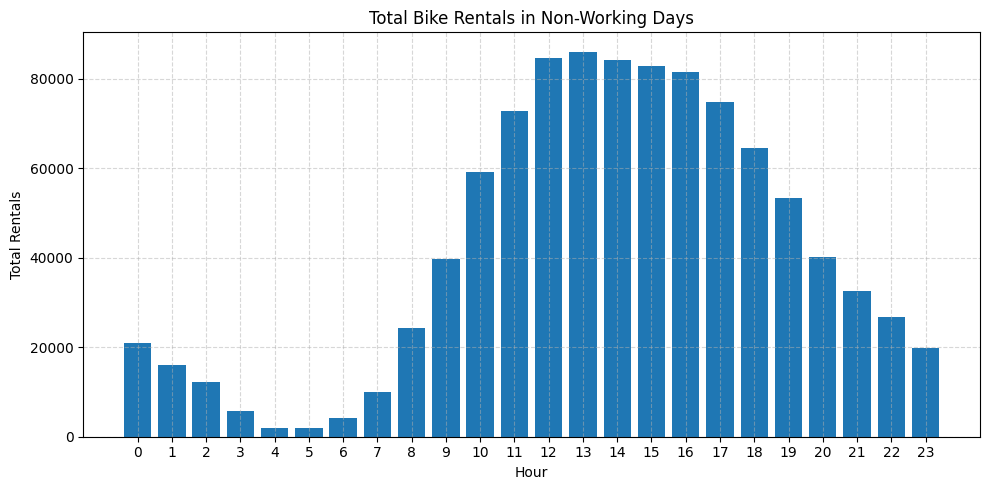

In [24]:
plt.figure(figsize=(10, 5))

plt.bar(
    non_working_days['hr'],
    non_working_days['cnt'],
)

plt.title('Total Bike Rentals in Non-Working Days')
plt.xlabel('Hour')
plt.ylabel('Total Rentals')
plt.xticks(range(24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

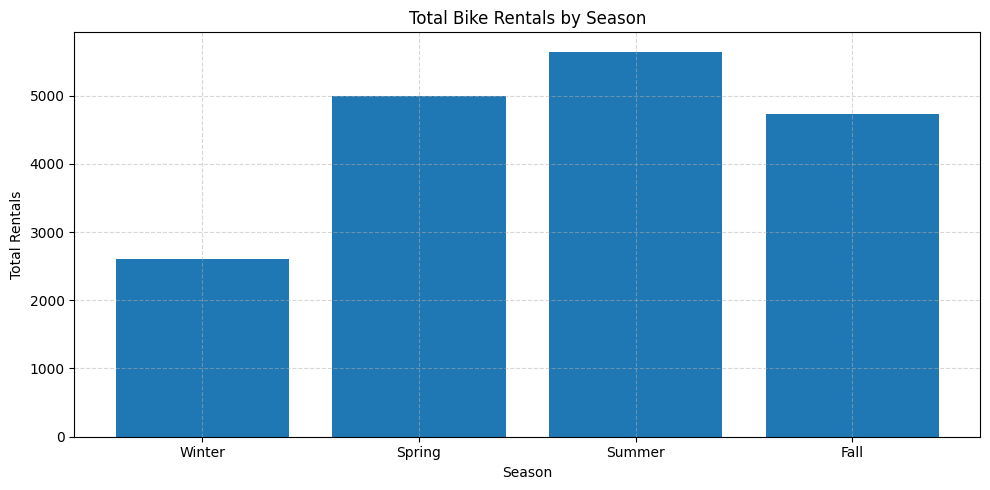

In [25]:
plt.figure(figsize=(10, 5))

plt.bar(
    rental_by_season['season'],
    rental_by_season['cnt'],
)

plt.title('Total Bike Rentals by Season')
plt.xlabel('Season')
plt.ylabel('Total Rentals')
plt.xticks(
    [1, 2, 3, 4],
    ['Winter', 'Spring', 'Summer', 'Fall']
)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('season.png', dpi=300)
plt.show()

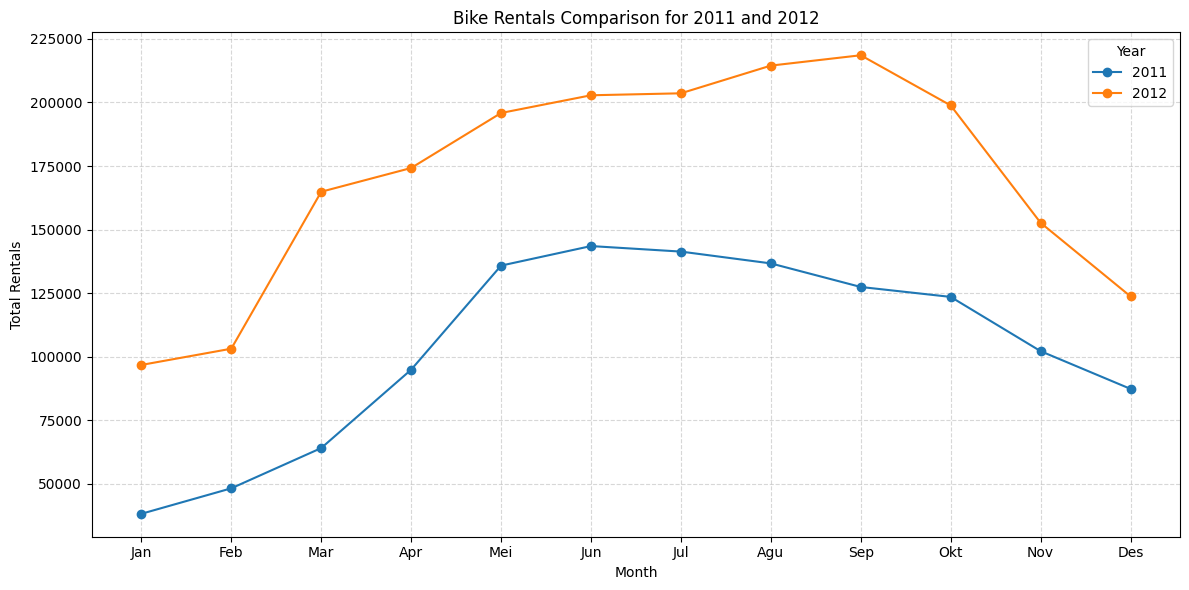

In [26]:
import matplotlib.pyplot as plt
month_names = [
    'Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun',
    'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des'
]

plt.figure(figsize=(12, 6))

for yr, label in [(0, '2011'), (1, '2012')]:
    data = rented_comp[rented_comp['yr'] == yr]

    plt.plot(
        data['mnth'],
        data['cnt'],
        marker='o',
        label=label
    )

plt.title('Bike Rentals Comparison for 2011 and 2012')
plt.xlabel('Month')
plt.ylabel('Total Rentals')
plt.xticks(range(1, 13), month_names)
plt.legend(title='Year')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('growth.png', dpi=300)
plt.show()

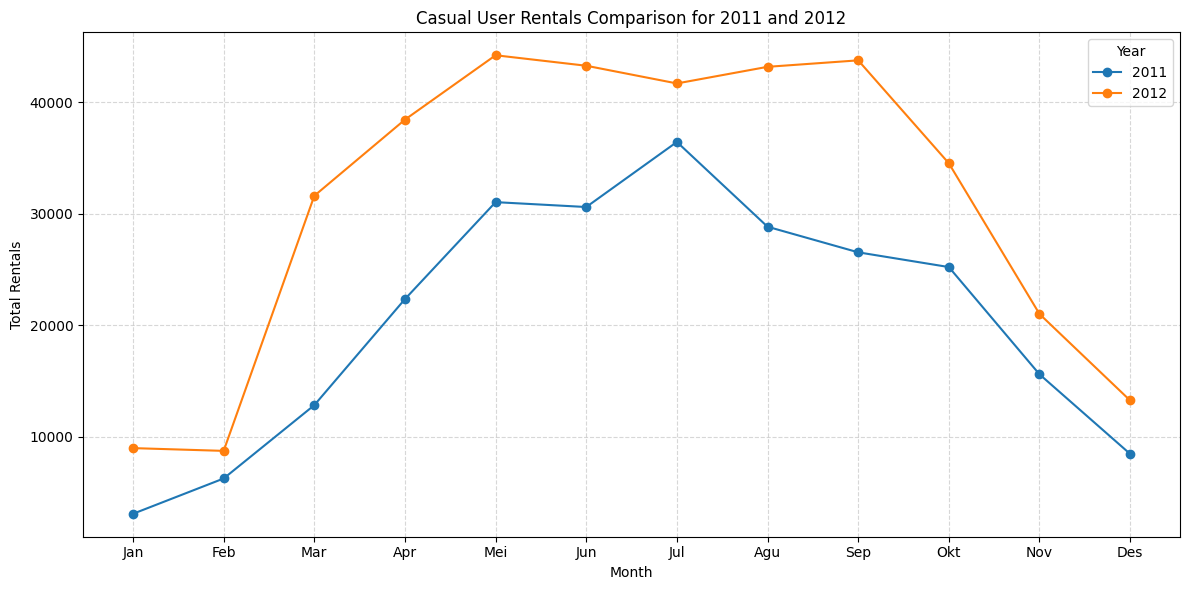

In [27]:
import matplotlib.pyplot as plt
month_names = [
    'Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun',
    'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des'
]

plt.figure(figsize=(12, 6))

for yr, label in [(0, '2011'), (1, '2012')]:
    data = total_rent[total_rent['yr'] == yr]

    plt.plot(
        data['mnth'],
        data['casual'],
        marker='o',
        label=label
    )

plt.title('Casual User Rentals Comparison for 2011 and 2012')
plt.xlabel('Month')
plt.ylabel('Total Rentals')
plt.xticks(range(1, 13), month_names)
plt.legend(title='Year')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

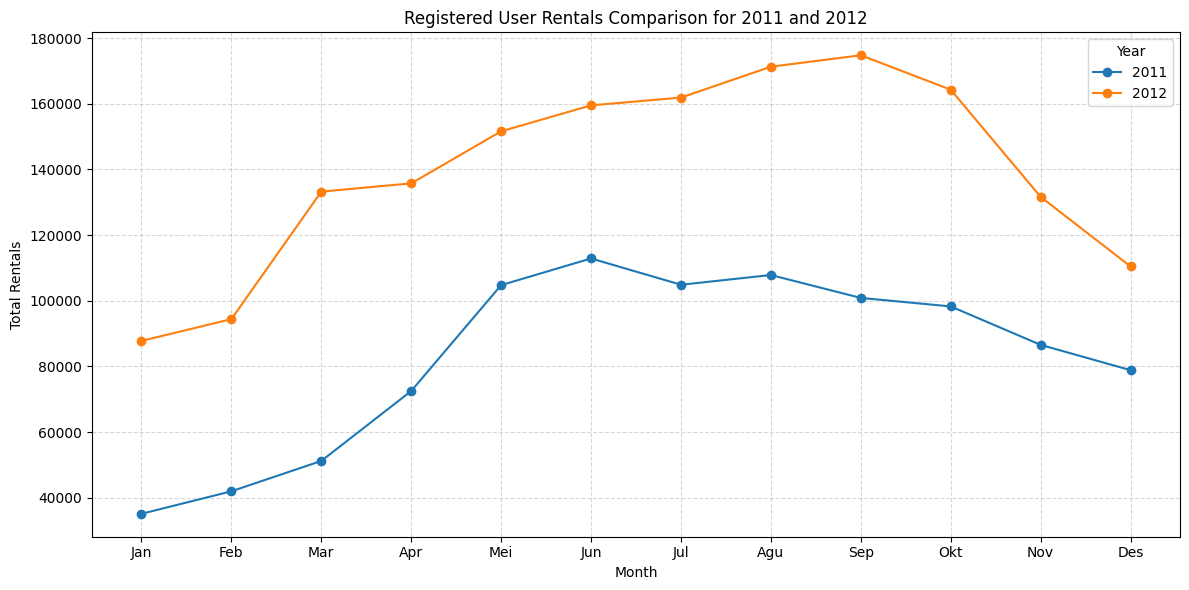

In [28]:
import matplotlib.pyplot as plt
month_names = [
    'Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun',
    'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des'
]

plt.figure(figsize=(12, 6))

for yr, label in [(0, '2011'), (1, '2012')]:
    data = total_rent[total_rent['yr'] == yr]

    plt.plot(
        data['mnth'],
        data['registered'],
        marker='o',
        label=label
    )

plt.title('Registered User Rentals Comparison for 2011 and 2012')
plt.xlabel('Month')
plt.ylabel('Total Rentals')
plt.xticks(range(1, 13), month_names)
plt.legend(title='Year')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

## Conclusion

- **Conclusion 1:** On working days, bike rentals show two peaks, at 08:00 and 17:00, with the highest peak at 17:00. On non-working days, rentals peak at around 13:00 and remain fairly busy from 10:00 to 19:00. The company should ensure that enough bikes are available during these peak hours to keep the service running optimally.

- **Conclusion 2:** Average daily bike rentals are highest in summer at 5644 bikes per day, followed by spring (4992), fall (4728), and lowest in winter (2604). The largest increase occurs from winter to spring, at 92%.

- **Conclusion 3:** Total bike rentals grew by 64.9%, from 1,243,103 in 2011 to 2,049,576 in 2012. The highest growth occurred in March (+157.44%), while the lowest growth occurred in June (+41.33%). The large growth in early 2012 is partly due to the low rental base in early 2011.